In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [29]:
data_path = Path("../data/raw/AAPL_2018_2025.csv")

df = pd.read_csv(
    data_path,
    index_col="Date",
    parse_dates=True
)

df = df.sort_index()

print(df.shape)
display(df.head())

(2011, 6)


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2018-01-02,40.232388,43.064999,43.075001,42.314999,42.540001,102223600
2018-01-03,40.225365,43.057499,43.637501,42.990002,43.132500,118071600
2018-01-04,40.412209,43.257500,43.367500,43.020000,43.134998,89738400
2018-01-05,40.872318,43.750000,43.842499,43.262501,43.360001,94640000
2018-01-08,40.720516,43.587502,43.902500,43.482498,43.587502,82271200


In [30]:
# create features and targets

forecast_df = pd.DataFrame(index=df.index)

forecast_df["Close"] = df["Close"]

# Next trading session's closing price
forecast_df["Target"] = df["Close"].shift(-1)

display(forecast_df.head())
display(forecast_df.tail())

,Close,Target
Date,,
2018-01-02,43.064999,43.057499
2018-01-03,43.057499,43.257500
2018-01-04,43.257500,43.750000
2018-01-05,43.750000,43.587502
2018-01-08,43.587502,43.582500


,Close,Target
Date,,
2025-12-24,273.809998,273.399994
2025-12-26,273.399994,273.760010
2025-12-29,273.760010,273.079987
2025-12-30,273.079987,271.859985
2025-12-31,271.859985,NaN


In [31]:
#remove observations without known targets

forecast_df = forecast_df.dropna(subset=["Target"]).copy()

print("Usable observations:", len(forecast_df))
print("Missing targets:", forecast_df["Target"].isna().sum())

Usable observations: 2010
Missing targets: 0


In [32]:
# chronological splits
# 70% train, 15% validation, 15% test

n = len(forecast_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = forecast_df.iloc[:train_end].copy()
val_df = forecast_df.iloc[train_end:val_end].copy()
test_df = forecast_df.iloc[val_end:].copy()

# Exclude labels that cross split boundaries
train_df = train_df.iloc[:-1].copy()
val_df = val_df.iloc[:-1].copy()

print("Training observations:", len(train_df))
print("Validation observations:", len(val_df))
print("Testing observations:", len(test_df))

print("\nTraining:", train_df.index.min(), "to", train_df.index.max())
print("Validation:", val_df.index.min(), "to", val_df.index.max())
print("Testing:", test_df.index.min(), "to", test_df.index.max())

Training observations: 1406
Validation observations: 300
Testing observations: 302

Training: 2018-01-02 00:00:00 to 2023-08-03 00:00:00
Validation: 2023-08-07 00:00:00 to 2024-10-14 00:00:00
Testing: 2024-10-16 00:00:00 to 2025-12-30 00:00:00


In [33]:
# Persistence baseline: next close = current close
val_predictions = val_df["Close"].copy()
test_predictions = test_df["Close"].copy()

# Actual next-session closing prices
val_actual = val_df["Target"]
test_actual = test_df["Target"]

print("Validation predictions:", len(val_predictions))
print("Testing predictions:", len(test_predictions))

Validation predictions: 300
Testing predictions: 302


In [34]:
# validation metric calculations
val_mae = mean_absolute_error(
    val_actual,
    val_predictions
)

val_rmse = np.sqrt(
    mean_squared_error(val_actual, val_predictions)
)

print("PERSISTENCE BASELINE — VALIDATION")
print(f"MAE:  ${val_mae:.4f}")
print(f"RMSE: ${val_rmse:.4f}")

PERSISTENCE BASELINE — VALIDATION
MAE:  $2.0119
RMSE: $2.7477


In [35]:
# test metrics calcs

test_mae = mean_absolute_error(
    test_actual,
    test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(test_actual, test_predictions)
)

print("PERSISTENCE BASELINE — TEST")
print(f"MAE:  ${test_mae:.4f}")
print(f"RMSE: ${test_rmse:.4f}")

PERSISTENCE BASELINE — TEST
MAE:  $2.6932
RMSE: $4.0568


In [36]:
test_results = pd.DataFrame({
    "Prediction_Date": test_df.index,
    "Actual_Close": test_actual.to_numpy(),
    "Predicted_Close": test_predictions.to_numpy()
})

# The next trading session is the target date
test_results["Target_Date"] = df.index[
    df.index.get_indexer(test_df.index) + 1
]

test_results = test_results.set_index("Target_Date")

display(test_results.head())

,Prediction_Date,Actual_Close,Predicted_Close
Target_Date,,,
2024-10-17,2024-10-16,232.149994,231.779999
2024-10-18,2024-10-17,235.000000,232.149994
2024-10-21,2024-10-18,236.479996,235.000000
2024-10-22,2024-10-21,235.860001,236.479996
2024-10-23,2024-10-22,230.759995,235.860001


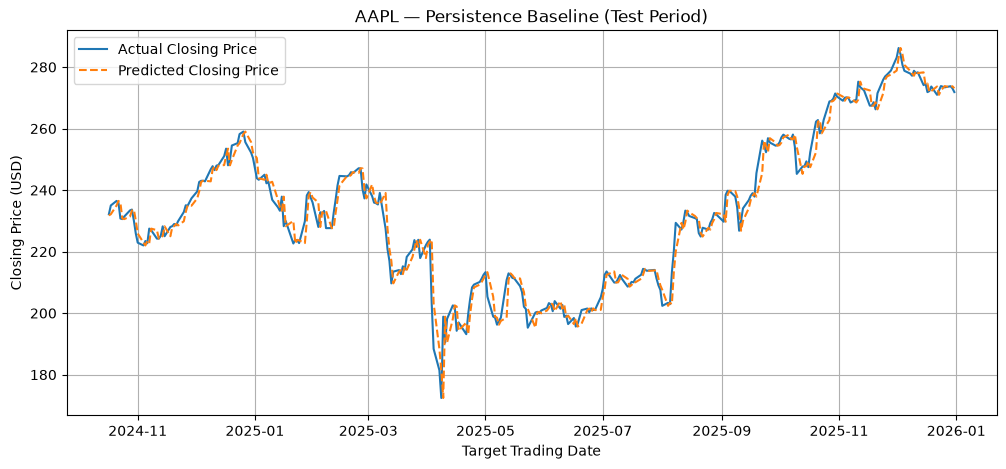

In [37]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_results.index,
    test_results["Actual_Close"],
    label="Actual Closing Price"
)

plt.plot(
    test_results.index,
    test_results["Predicted_Close"],
    label="Predicted Closing Price",
    linestyle="--"
)

plt.title("AAPL — Persistence Baseline (Test Period)")
plt.xlabel("Target Trading Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
# baseline validation:

# Predictions should equal the previous session's close
assert np.allclose(
    test_results["Predicted_Close"].to_numpy(),
    test_df["Close"].to_numpy()
)

# Actuals should equal the following session's close
assert np.allclose(
    test_results["Actual_Close"].to_numpy(),
    test_df["Target"].to_numpy()
)

# Target dates must occur after prediction dates
assert (
    test_results.index.to_numpy()
    > test_df.index.to_numpy()
).all()

print("Baseline prediction alignment verified!")

Baseline prediction alignment verified!


In [ ]:
baseline_results = pd.DataFrame({
    "Dataset": ["Validation", "Test"],
    "Model": ["Persistence", "Persistence"],
    "MAE": [val_mae, test_mae],
    "RMSE": [val_rmse, test_rmse]
})

display(baseline_results.round(4))